# Kaikōura 2016 earthquake — landslide screening of SH1 and Inland Route 70

**What this notebook does, end to end**
1. Downloads the open pretrained landslide model (Monopoli et al., 2024) and its weights.
2. Builds the road corridors (SH1 North, SH1 South, Inland Route 70) from OpenStreetMap.
3. Downloads pre- and post-earthquake Sentinel-2 imagery for each 2.56 km tile from Google Earth Engine and runs the model (no retraining, threshold 0.5).
4. Converts detections into 200 m road-segment condition classes.
5. Validates against GNS Science's independent landslide inventory (≤ 50 m / ≤ 100 m matching).
6. **Added analyses**: km per class, recall-vs-tolerance curve, pixel-level precision/recall/F1/IoU (if GNS polygons exist), polygon support, publication-style maps.



In [1]:
# CELL 1 — SETUP

%pip -q install "segmentation-models-pytorch==0.5.0" "albumentations==2.0.8" loguru timm einops rasterio earthengine-api geopandas shapely pyproj gdown requests

import os, sys, json, math, time, subprocess
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, requests, rasterio
from rasterio.transform import from_origin
from rasterio.features import shapes, rasterize
from shapely.geometry import box, shape, LineString, MultiLineString, Point
from shapely.ops import unary_union, linemerge, substring
import matplotlib.pyplot as plt
from IPython.display import display

EE_PROJECT = "earthenginetest-504004"

WORK = Path("/content/work")
for sub in ["checkpoints", "raw", "SH1/tile_results", "R70/tile_results", "figures", "cache"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
SH1_OUT, R70_OUT, FIG_OUT = WORK / "SH1", WORK / "R70", WORK / "figures"

REPO = Path("/content/igarss-landslide-delineation")
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/links-ads/igarss-landslide-delineation", str(REPO)], check=True)
sys.path.insert(0, str(REPO))
print("Model repo:", REPO, "| exists:", REPO.exists())

import ee
EE_PROJECT = EE_PROJECT.strip().strip("'\"")
assert "YOUR-" not in EE_PROJECT, "Set EE_PROJECT to your own Earth Engine project ID first."
ee.Authenticate()
try:
    ee.Initialize(project=EE_PROJECT); ee.Number(1).getInfo()
except Exception as e:
    raise RuntimeError("Earth Engine rejected project '" + EE_PROJECT + "'. Use the project ID shown at "
                       "code.earthengine.google.com (profile icon, top right), signed in with the SAME Google account "
                       "you just authorised. Details: " + str(e)[:200])
print("Earth Engine connected:", EE_PROJECT)
print("Work folder:", WORK)

Model repo: /content/igarss-landslide-delineation | exists: True
Earth Engine connected: earthenginetest-504004
Work folder: /content/work


## Step 1 — Pretrained model (official weights, no retraining)

In [2]:
# CELL 2 — DOWNLOAD THE PRETRAINED CHECKPOINT

import gdown
CK_DIR = WORK / "checkpoints"
FOLDER_URL = "https://drive.google.com/drive/folders/1351hEZeY2T67aGhD-ONNyLN8Cq0cAfzX"   # from the model repo README

if not list(CK_DIR.rglob("*.pt")):
    gdown.download_folder(FOLDER_URL, output=str(CK_DIR), quiet=False, use_cookies=False)

pts = sorted(CK_DIR.rglob("*.pt"))
print("Checkpoints found:")
for p in pts: print("  ", p.relative_to(CK_DIR), f"({p.stat().st_size/1e6:.0f} MB)")

CKPT_NAME = None     # SETTINGS: put an exact file name here to override the automatic choice
if CKPT_NAME:
    CKPT = next(p for p in pts if p.name == CKPT_NAME)
else:
    pick = [p for p in pts if "diff" in p.name.lower() and ("r50" in p.name.lower() or "resnet50" in p.name.lower())]
    assert pick, "Could not auto-select a U-Net-Siam-Diff ResNet-50 file; set CKPT_NAME above."
    CKPT = pick[0]
print("\n Using checkpoint:", CKPT.name)

Retrieving folder contents


Processing file 1VIMgcq_5SyLWjo2jpMElvvWbkY9TbiLq bbunet_r18.pt
Processing file 114YYaP3vA-xGf0I6fC2iBcfCzQmtZcyr bit.pt
Processing file 1oP5UTor8AnI2NAtpHYgUPpOCajZKjTxE seifnet.pt
Processing file 1K7Qo2eCa1gbj8BntxJLeV3YUXfvZUBZD tinycd.pt
Processing file 1Z6FOqWJ2ZmiJetrP48pXZiHSzizjZKdj unet_r50_diff.pt


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1VIMgcq_5SyLWjo2jpMElvvWbkY9TbiLq
From (redirected): https://drive.google.com/uc?id=1VIMgcq_5SyLWjo2jpMElvvWbkY9TbiLq&confirm=t&uuid=44cf97c6-56ce-4272-94b9-15a6d1a8364f
To: /content/work/checkpoints/bbunet_r18.pt
100%|██████████| 141M/141M [00:05<00:00, 27.8MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=114YYaP3vA-xGf0I6fC2iBcfCzQmtZcyr
From (redirected): https://drive.google.com/uc?id=114YYaP3vA-xGf0I6fC2iBcfCzQmtZcyr&confirm=t&uuid=cd5317e0-297b-4b4b-839a-3669af24626d
To: /content/work/checkpoints/bit.pt
100%|██████████| 49.9M/49.9M [00:01<00:00, 44.2MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1oP5UTor8AnI2NAtpHYgUPpOCajZKjTxE
From (redirected): https://drive.google.com/uc?id=1oP5UTor8AnI2NAtpHYgUPpOCajZKjTxE&confirm=t&uuid=eb3ca71c-a21b-407e-9355-dac9541538f1
To: /conten

Checkpoints found:
   bbunet_r18.pt (141 MB)
   bit.pt (50 MB)
   seifnet.pt (115 MB)
   tinycd.pt (1 MB)
   unet_r50_diff.pt (131 MB)

 Using checkpoint: unet_r50_diff.pt



Download completed


In [3]:
# CELL 3 — LOAD THE MODEL (with compatibility fixes)

import torch
from src.model_utils import make_model

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
hparams = ckpt["hparams"]
hparams.PRETRAINED_ENCODER_WEIGHTS = None
print("Checkpoint: model =", hparams.MODEL, "| encoder =", hparams.ENCODER,
      "| fusion =", hparams.FUSION_MODULE, "| bands =", len(hparams.BANDS))

model = make_model(hparams)
try:
    model.load_state_dict(ckpt["state_dict"])
except RuntimeError:
    model.load_state_dict({k.replace("model.", "", 1): v for k, v in ckpt["state_dict"].items()})
model.eval().to(device)

# Compatibility fix: the repo calls decoder(*features); the installed library expects decoder(features)
class _DecoderWrap(torch.nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
    def forward(self, *features):
        if len(features) == 1 and isinstance(features[0], (list, tuple)):
            features = tuple(features[0])
        return self.d(list(features))
model.decoder = _DecoderWrap(model.decoder)

def _unwrap(out):
    if isinstance(out, (tuple, list)): out = out[0]
    if isinstance(out, dict): out = next(iter(out.values()))
    return out

def run_model(a, b):
    dem = torch.zeros_like(a[:, :1])          # unused placeholder (ADD_DEM = False)
    with torch.no_grad():
        return _unwrap(model(a, b, dem))

# quick self-test
test = torch.rand(1, 12, 384, 384, device=device)
out = run_model(test, test)
print(" Model works. Output shape:", tuple(out.shape))
assert tuple(out.shape[-2:]) == (384, 384)

def predict_prob(pre, post):
    """pre/post: float arrays (12, H, W) scaled 0-1 -> landslide probability (H, W)."""
    a = torch.from_numpy(pre[None]).float().to(device)
    b = torch.from_numpy(post[None]).float().to(device)
    out = run_model(a, b)[0]
    p = torch.softmax(out, 0)[1] if out.ndim == 3 and out.shape[0] == 2 else torch.sigmoid(out.squeeze())
    return p.cpu().numpy()
print("Model ready.")

/content/igarss-landslide-delineation/src/models/bit/networks.py:234: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if with_pos is 'learned':
/content/igarss-landslide-delineation/src/models/bit/networks.py:265: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if self.pool_mode is 'max':
/content/igarss-landslide-delineation/src/models/bit/networks.py:267: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif self.pool_mode is 'ave':


Device: cuda
Checkpoint: model = unet | encoder = resnet50 | fusion = diff_features | bands = 12
 Model works. Output shape: (1, 1, 384, 384)
Model ready.


## Step 2 — Road corridors (OpenStreetMap)

   overpass-api.de failed: 502 Server Error: Bad Gateway for url: https://overpass-api.de/api/interpreter
   OK from overpass.kumi.systems: 141 ways
   OK from overpass-api.de: 91 ways
OSM ways: SH1 = 141 | Route 70 = 91
SH1 North: 57.1 km
SH1 South: 37.5 km
Route 70: 96.8 km
Reference: the report gives Route 70 as 77.8 km. A large difference means extra/missing OSM ways - check the map below.


/tmp/ipykernel_3598/3802724183.py:50: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  out = out[out.geometry.notna() & ~out.geometry.is_empty & (out.geometry.length > 0)]
/tmp/ipykernel_3598/3802724183.py:50: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  out = out[out.geometry.notna() & ~out.geometry.is_empty & (out.geometry.length > 0)]
/tmp/ipykernel_3598/3802724183.py:50: UserWarning: GeoSeries.notna() previ

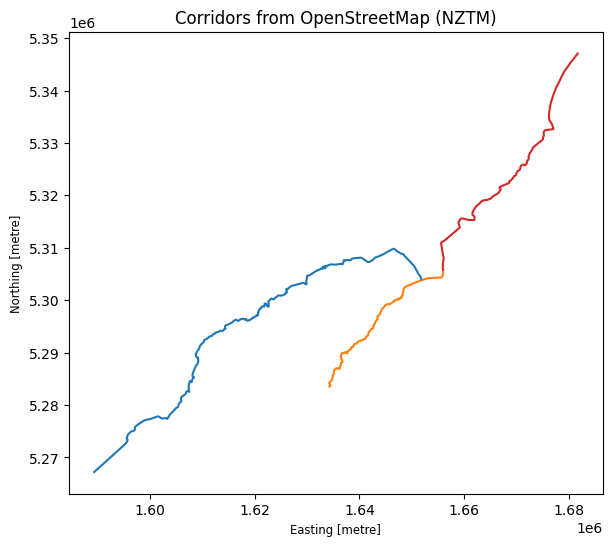

In [4]:
# CELL 4 — ROAD GEOMETRY FROM OPENSTREETMAP (Overpass API)

OVERPASS_SERVERS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
    "https://overpass.private.coffee/api/interpreter",
]
HEADERS = {"User-Agent": "GEOG761-student-project/1.0 (university coursework)", "Accept": "*/*"}
DIVIDER_LAT = -42.40          # SETTINGS: SH1 North / South split (as in the report)

def overpass_lines(bbox, ref_regex, cache_name):
    cache = WORK / "cache" / cache_name
    if cache.exists():
        return gpd.read_file(cache)
    s, w, n, e = bbox
    q = f'[out:json][timeout:180];way["highway"]["ref"~"{ref_regex}"]({s},{w},{n},{e});out geom;'
    last_err = None
    for attempt in range(2):
        for url in OVERPASS_SERVERS:
            try:
                r = requests.post(url, data={"data": q}, headers=HEADERS, timeout=240)
                r.raise_for_status()
                elements = r.json()["elements"]
                lines = [LineString([(p["lon"], p["lat"]) for p in el["geometry"]])
                         for el in elements if len(el.get("geometry", [])) > 1]
                if not lines:
                    raise ValueError("server returned no road geometry")
                g = gpd.GeoDataFrame(geometry=lines, crs="EPSG:4326")
                g.to_file(cache, driver="GeoJSON")
                print(f"   OK from {url.split('/')[2]}: {len(g)} ways")
                return g
            except Exception as e_:
                last_err = e_
                print(f"   {url.split('/')[2]} failed: {str(e_)[:90]}")
        time.sleep(10)
    raise RuntimeError(f"All Overpass servers failed. Wait a minute and re-run this cell. Last error: {last_err}")

sh1_raw = overpass_lines((-42.60, 173.40, -42.05, 174.05), r"^(SH ?)?1$", "sh1_osm.geojson")
r70_raw = overpass_lines((-42.75, 172.90, -42.30, 173.75), r"^(SH ?)?70$", "r70_osm.geojson")
print("OSM ways: SH1 =", len(sh1_raw), "| Route 70 =", len(r70_raw))

def merge_lines(g):
    u = unary_union(g.to_crs(2193).geometry)
    m = linemerge(u) if u.geom_type == "MultiLineString" else u
    return gpd.GeoDataFrame(geometry=[m], crs=2193)

def clip_lines(g4326, region):
    out = g4326.copy()
    out["geometry"] = out.geometry.intersection(region)
    out = out[out.geometry.notna() & ~out.geometry.is_empty & (out.geometry.length > 0)]
    return merge_lines(out)

sh1_north = clip_lines(sh1_raw, box(172, DIVIDER_LAT, 175, -41))
sh1_south = clip_lines(sh1_raw, box(172, -44, 175, DIVIDER_LAT))
route70_nztm = merge_lines(r70_raw)
for n_, g_ in [("SH1 North", sh1_north), ("SH1 South", sh1_south), ("Route 70", route70_nztm)]:
    print(f"{n_}: {g_.geometry.length.sum()/1000:.1f} km")
print("Reference: the report gives Route 70 as 77.8 km. A large difference means extra/missing OSM ways - check the map below.")

fig, ax = plt.subplots(figsize=(7, 6))
for g_, c in [(sh1_north, "tab:red"), (sh1_south, "tab:orange"), (route70_nztm, "tab:blue")]:
    g_.plot(ax=ax, color=c, lw=1.5)
ax.set_title("Corridors from OpenStreetMap (NZTM)")
ax.set_aspect("equal")
plt.show()

OSM ways: SH1 = 141 | Route 70 = 91
SH1 North: 57.1 km
SH1 South: 37.5 km
Route 70: 96.8 km
Reference: the report gives Route 70 as 77.8 km. A large difference means extra/missing OSM ways – inspect the map below.


/tmp/ipykernel_3598/2452740934.py:29: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  out = out[out.geometry.notna() & ~out.geometry.is_empty & (out.geometry.length > 0)]
/tmp/ipykernel_3598/2452740934.py:29: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  out = out[out.geometry.notna() & ~out.geometry.is_empty & (out.geometry.length > 0)]
/tmp/ipykernel_3598/2452740934.py:29: UserWarning: GeoSeries.notna() previ

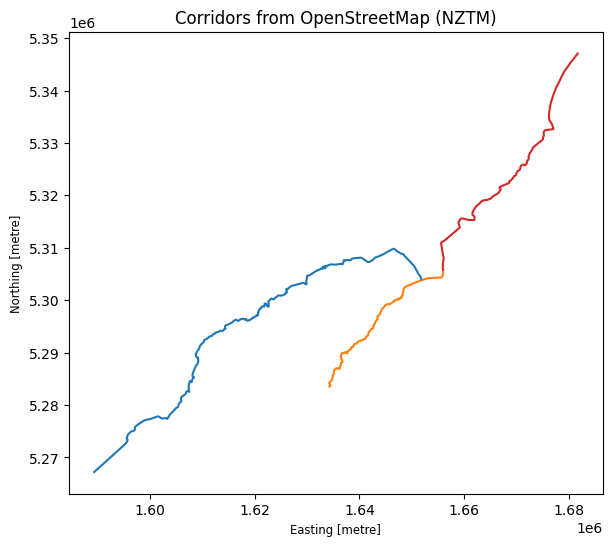

In [5]:
# CELL 4 — ROAD GEOMETRY FROM OPENSTREETMAP (Overpass API)

OVERPASS = "https://overpass-api.de/api/interpreter"
DIVIDER_LAT = -42.40          # SETTINGS: SH1 North / South split (as in the report)

def overpass_lines(bbox, ref_regex, cache_name):
    cache = WORK / "cache" / cache_name
    if cache.exists(): return gpd.read_file(cache)
    s, w, n, e = bbox
    q = f'[out:json][timeout:180];way["highway"]["ref"~"{ref_regex}"]({s},{w},{n},{e});out geom;'
    r = requests.post(OVERPASS, data={"data": q}, timeout=240); r.raise_for_status()
    lines = [LineString([(p["lon"], p["lat"]) for p in el["geometry"]])
             for el in r.json()["elements"] if len(el.get("geometry", [])) > 1]
    g = gpd.GeoDataFrame(geometry=lines, crs="EPSG:4326")
    g.to_file(cache, driver="GeoJSON"); return g

sh1_raw = overpass_lines((-42.60, 173.40, -42.05, 174.05), r"^(SH ?)?1$", "sh1_osm.geojson")
r70_raw = overpass_lines((-42.75, 172.90, -42.30, 173.75), r"^(SH ?)?70$", "r70_osm.geojson")
print("OSM ways: SH1 =", len(sh1_raw), "| Route 70 =", len(r70_raw))
assert len(sh1_raw) and len(r70_raw), "Overpass returned nothing – retry in a minute, or adjust the ref regex."

def merge_lines(g):
    u = unary_union(g.to_crs(2193).geometry)
    m = linemerge(u) if u.geom_type == "MultiLineString" else u
    return gpd.GeoDataFrame(geometry=[m], crs=2193)

def clip_lines(g4326, region):
    out = g4326.copy(); out["geometry"] = out.geometry.intersection(region)
    out = out[out.geometry.notna() & ~out.geometry.is_empty & (out.geometry.length > 0)]
    return merge_lines(out)

sh1_north = clip_lines(sh1_raw, box(172, DIVIDER_LAT, 175, -41))
sh1_south = clip_lines(sh1_raw, box(172, -44, 175, DIVIDER_LAT))
route70_nztm = merge_lines(r70_raw)
for n_, g_ in [("SH1 North", sh1_north), ("SH1 South", sh1_south), ("Route 70", route70_nztm)]:
    print(f"{n_}: {g_.geometry.length.sum()/1000:.1f} km")
print("Reference: the report gives Route 70 as 77.8 km. A large difference means extra/missing OSM ways – inspect the map below.")

fig, ax = plt.subplots(figsize=(7, 6))
for g_, c in [(sh1_north, "tab:red"), (sh1_south, "tab:orange"), (route70_nztm, "tab:blue")]:
    g_.plot(ax=ax, color=c, lw=1.5)
ax.set_title("Corridors from OpenStreetMap (NZTM)"); ax.set_aspect("equal"); plt.show()

## Step 3 — Tiles, Sentinel-2 download and CNN inference
`SETTINGS` below control the imagery windows. Pre-event: before 14 Nov 2016. Post-event: after the earthquake. Clouds are masked with the Sentinel-2 QA60 band and a median composite is used per window.

In [6]:
# CELL 5 — TILE PLAN (2.56 km cores on the NZTM grid, 1 km road buffer)

CORE, PX, CTX, TILE_PX = 2560, 10, 640, 384          # core size (m), pixel (m), context (m), tile size (px)

def plan_tiles(road_geom, buffer_m=1000):
    buf = road_geom.buffer(buffer_m); x0, y0, x1, y1 = buf.bounds
    tiles = []
    for ix in range(math.floor(x0/CORE), math.floor(x1/CORE) + 1):
        for iy in range(math.floor(y0/CORE), math.floor(y1/CORE) + 1):
            if box(ix*CORE, iy*CORE, (ix+1)*CORE, (iy+1)*CORE).intersects(buf):
                tiles.append((ix, iy))
    return tiles

sh1_union = unary_union([sh1_north.geometry.iloc[0], sh1_south.geometry.iloc[0]])
r70_union = route70_nztm.geometry.iloc[0]
GROUPS = {"SH1": {"road": sh1_union, "out": SH1_OUT, "tiles": plan_tiles(sh1_union)},
          "Route 70": {"road": r70_union, "out": R70_OUT, "tiles": plan_tiles(r70_union)}}
for k, v in GROUPS.items(): print(k, "tiles:", len(v["tiles"]))
print("(The report used 82 tiles for SH1 and 58 for Route 70; small differences are expected.)")

SH1 tiles: 79
Route 70 tiles: 73
(The report used 82 tiles for SH1 and 58 for Route 70; small differences are expected.)


In [7]:
# CELL 6 — SENTINEL-2 DOWNLOAD + CNN INFERENCE (resumable)

TEST_TILES = None
PRE_WINDOW  = ("2016-10-15", "2016-11-13")   # SETTINGS: before the 14 Nov 2016 earthquake
POST_WINDOW = ("2016-11-15", "2016-12-10")   # SETTINGS: after the earthquake
MAX_CLOUDY_PCT = 70
THRESHOLD = 0.5
BANDS = ["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B9","B11","B12"]   # the 12 bands used by the model

def composite(region, start, end):
    col = (ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(region).filterDate(start, end)
           .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUDY_PCT)))
    def mask(img):
        qa = img.select("QA60")
        ok = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
        return img.select(BANDS).updateMask(ok)
    return col.map(mask).median()

def fetch_tile(ix, iy, retries=4):
    cache = WORK / "raw" / f"C_{ix}_{iy}.tif"
    if cache.exists(): return cache
    x0, y0 = ix*CORE - CTX, iy*CORE - CTX
    x1, y1 = (ix+1)*CORE + CTX, (iy+1)*CORE + CTX
    region = ee.Geometry.Rectangle([x0, y0, x1, y1], "EPSG:2193", False)
    pre, post = composite(region, *PRE_WINDOW), composite(region, *POST_WINDOW)
    img = (pre.unmask(0).addBands(post.unmask(0))
           .addBands(pre.select("B4").mask().rename("v_pre")).addBands(post.select("B4").mask().rename("v_post"))
           .toInt16())
    for k in range(retries):
        try:
            url = img.getDownloadURL({"region": region, "crs": "EPSG:2193",
                                      "crs_transform": [PX, 0, x0, 0, -PX, y1], "format": "GEO_TIFF"})
            r = requests.get(url, timeout=300); r.raise_for_status()
            data = r.content
            if data[:2] == b"PK":
                import zipfile, io
                z = zipfile.ZipFile(io.BytesIO(data)); data = z.read(z.namelist()[0])
            cache.write_bytes(data); return cache
        except Exception as e:
            print(f"   retry {k+1}/{retries} for C_{ix}_{iy}: {str(e)[:100]}"); time.sleep(5*(k+1))
    raise RuntimeError(f"Download failed for tile C_{ix}_{iy}")

def process_tile(ix, iy, out_dir):
    tile_dir = out_dir / "tile_results" / f"C_{ix}_{iy}"; f_out = tile_dir / "binary.tif"
    if f_out.exists(): return "cached"
    tif = fetch_tile(ix, iy)
    with rasterio.open(tif) as s: arr = s.read().astype("float32")
    if arr.shape[1] < TILE_PX or arr.shape[2] < TILE_PX:
        pad = np.zeros((arr.shape[0], TILE_PX, TILE_PX), "float32")
        pad[:, :arr.shape[1], :arr.shape[2]] = arr[:, :TILE_PX, :TILE_PX]; arr = pad
    arr = arr[:, :TILE_PX, :TILE_PX]
    pre, post = np.clip(arr[:12]/10000, 0, 1), np.clip(arr[12:24]/10000, 0, 1)
    observed = (arr[24] > 0) & (arr[25] > 0)
    prob = predict_prob(pre, post)
    a, b = (TILE_PX - 256)//2, (TILE_PX - 256)//2 + 256        # 256-px core inside the 384-px tile
    pred = (prob[a:b, a:b] >= THRESHOLD).astype("uint8")
    out = np.full((256, 256), 255, "uint8"); obs_c = observed[a:b, a:b]; out[obs_c] = pred[obs_c]
    tile_dir.mkdir(parents=True, exist_ok=True)
    with rasterio.open(f_out, "w", driver="GTiff", height=256, width=256, count=1, dtype="uint8", crs="EPSG:2193",
                       transform=from_origin(ix*CORE, (iy+1)*CORE, PX, PX), nodata=255, compress="lzw") as dst:
        dst.write(out, 1)
    return f"{int(pred[obs_c].sum())} landslide px, {100*obs_c.mean():.0f}% observed"

t0 = time.time()
for name, g in GROUPS.items():
    todo = g["tiles"][:TEST_TILES] if TEST_TILES else g["tiles"]
    for k, (ix, iy) in enumerate(todo, 1):
        msg = process_tile(ix, iy, g["out"])
        print(f"[{name}] {k}/{len(todo)} C_{ix}_{iy}: {msg}  ({(time.time()-t0)/60:.1f} min)")


[SH1] 1/79 C_637_2063: 1834 landslide px, 100% observed  (0.1 min)


[SH1] 2/79 C_637_2064: 270 landslide px, 100% observed  (0.2 min)


[SH1] 3/79 C_638_2063: 1283 landslide px, 100% observed  (0.3 min)


[SH1] 4/79 C_638_2064: 14 landslide px, 100% observed  (0.4 min)


[SH1] 5/79 C_638_2065: 541 landslide px, 100% observed  (0.6 min)


...

[Route 70] 65/73 C_643_2073: 828 landslide px, 100% observed  (17.1 min)


[Route 70] 66/73 C_643_2074: 1377 landslide px, 100% observed  (17.3 min)
[Route 70] 67/73 C_644_2071: 422 landslide px, 100% observed  (17.3 min)
[Route 70] 68/73 C_644_2072: 658 landslide px, 100% observed  (17.3 min)


[Route 70] 69/73 C_644_2073: 790 landslide px, 100% observed  (17.6 min)


[Route 70] 70/73 C_644_2074: 562 landslide px, 100% observed  (17.9 min)
[Route 70] 71/73 C_645_2071: 156 landslide px, 100% observed  (17.9 min)
[Route 70] 72/73 C_645_2072: 155 landslide px, 100% observed  (17.9 min)


[Route 70] 73/73 C_645_2073: 520 landslide px, 100% observed  (18.0 min)


Most active tile: C_622_2060 with 18189 landslide pixels


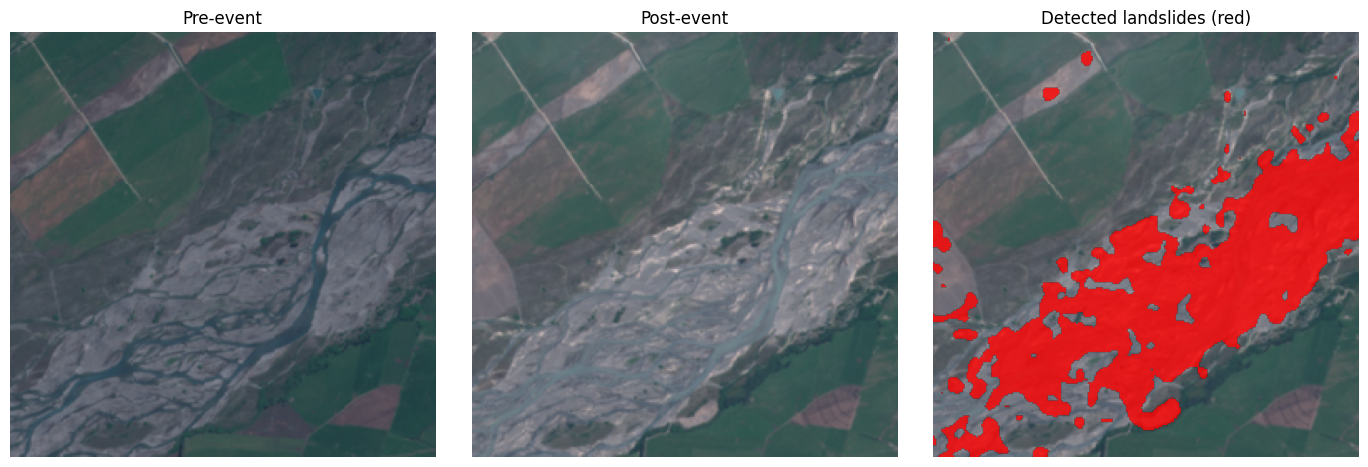

In [8]:
# CELL 7 — SANITY CHECK: pre / post / detections for the most active tile

best, best_n = None, -1
for g in GROUPS.values():
    for f in (g["out"] / "tile_results").glob("C_*/binary.tif"):
        with rasterio.open(f) as s: a = s.read(1)
        n = int((a == 1).sum())
        if n > best_n: best, best_n = f, n
print("Most active tile:", best.parent.name, "with", best_n, "landslide pixels")
ix, iy = map(int, best.parent.name.split("_")[1:])
with rasterio.open(WORK / "raw" / f"{best.parent.name}.tif") as s: raw = s.read().astype("float32")
rgb = lambda x: np.clip(x[[3, 2, 1]].transpose(1, 2, 0) / 3000, 0, 1)
with rasterio.open(best) as s: det = s.read(1)
a0 = (TILE_PX - 256)//2
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
axs[0].imshow(rgb(raw[:12])[a0:a0+256, a0:a0+256]); axs[0].set_title("Pre-event")
axs[1].imshow(rgb(raw[12:24])[a0:a0+256, a0:a0+256]); axs[1].set_title("Post-event")
axs[2].imshow(rgb(raw[12:24])[a0:a0+256, a0:a0+256]); axs[2].imshow(np.ma.masked_where(det != 1, det), cmap="autumn", alpha=.8)
axs[2].set_title("Detected landslides (red)")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()
# print("Sanity rule: red areas should sit on new bare/brown scars visible in the post image but not the pre image.")

## Step 4 — Polygons and 200 m road-segment classes

In [9]:
# CELL 8 — POLYGONS + ROAD CLASSIFICATION

IMPINGE_M, PRIORITY_M, MIN_VISIBLE = 20, 100, 0.5     # SETTINGS: class rules (documented in the report)
SEG_LEN = 200

def load_group(out_dir):
    polys, obs = [], {}
    for f in sorted((out_dir / "tile_results").glob("C_*/binary.tif")):
        with rasterio.open(f) as s: a = s.read(1); T = s.transform
        obs[f.parent.name] = (a != 255, T.c, T.f)
        for geom, v in shapes(a, mask=(a == 1), transform=T): polys.append(shape(geom))
    if not polys: return gpd.GeoDataFrame(geometry=[], crs=2193), obs
    merged = unary_union(polys); parts = list(merged.geoms) if hasattr(merged, "geoms") else [merged]
    return gpd.GeoDataFrame(geometry=parts, crs=2193), obs

pred_sh1, OBS_SH1 = load_group(SH1_OUT); pred70, OBS_R70 = load_group(R70_OUT)
pred_sh1.to_file(SH1_OUT / "03_predicted_landslides.geojson", driver="GeoJSON")
pred70.to_file(R70_OUT / "03_predicted_landslides.geojson", driver="GeoJSON")
print("CNN polygons — SH1:", len(pred_sh1), "| Route 70:", len(pred70), "(report: 713 and 642 – differences expected)")

def visible_at(x, y, OBS):
    tid = f"C_{math.floor(x/CORE)}_{math.floor(y/CORE)}"
    if tid not in OBS: return False
    m, x0, y0 = OBS[tid]; col, row = int((x - x0)//PX), int((y0 - y)//PX)
    return bool(m[row, col]) if 0 <= row < 256 and 0 <= col < 256 else False

def classify_roads(road_geom, preds, OBS):
    lines = list(road_geom.geoms) if hasattr(road_geom, "geoms") else [road_geom]
    polys = list(preds.geometry); from shapely.strtree import STRtree
    tree = STRtree(polys) if polys else None
    rows = []
    for line in lines:
        L = line.length
        for k, s0 in enumerate(np.arange(0, L, SEG_LEN)):
            seg = substring(line, s0, min(s0 + SEG_LEN, L))
            if seg.length < 20: continue
            samples = [seg.interpolate(d) for d in np.arange(0, seg.length, PX)] or [seg.centroid]
            vis = float(np.mean([visible_at(p.x, p.y, OBS) for p in samples]))
            dist = seg.distance(polys[int(tree.nearest(seg))]) if tree is not None else np.inf
            cls = ("possible_impingement" if dist <= IMPINGE_M else "inspection_priority" if dist <= PRIORITY_M
                   else "unknown_insufficient_imagery" if vis < MIN_VISIBLE else "no_detected_landslide_not_safe")
            rows.append({"geometry": seg, "length_m": seg.length, "distance_to_detection_m": round(float(dist), 1),
                         "visible_fraction": round(vis, 2), "class": cls})
    return gpd.GeoDataFrame(rows, crs=2193)

sh1_assess = classify_roads(sh1_union, pred_sh1, OBS_SH1); r70_assess = classify_roads(r70_union, pred70, OBS_R70)
sh1_assess.to_file(SH1_OUT / "04_SH1_road_assessment.geojson", driver="GeoJSON")
r70_assess.to_file(R70_OUT / "04_SH1_road_assessment.geojson", driver="GeoJSON")
print("Segments — SH1:", len(sh1_assess), "| Route 70:", len(r70_assess))
display(pd.DataFrame({"SH1 segments": sh1_assess["class"].value_counts(), "Route 70 segments": r70_assess["class"].value_counts()}).fillna(0).astype(int))

CNN polygons — SH1: 993 | Route 70: 1014 (report: 713 and 642 – differences expected)
Segments — SH1: 475 | Route 70: 484


,SH1 segments,Route 70 segments
class,,
no_detected_landslide_not_safe,296,344
possible_impingement,100,74
inspection_priority,79,66


## Step 5 — Validation against the GNS Science landslide inventory
GNS source points are used **only now, after inference**. Matched ≤ 50 m, near 50–100 m, missed > 100 m. A point is *observed* only if the model had cloud-free pre and post imagery there.

In [10]:
# CELL 9 — GNS VALIDATION

CORRIDORS = {
    "SH1 North": {"roads": sh1_north, "pred": pred_sh1[pred_sh1.to_crs(4326).geometry.representative_point().y >= DIVIDER_LAT].copy(), "obs": OBS_SH1},
    "SH1 South": {"roads": sh1_south, "pred": pred_sh1[pred_sh1.to_crs(4326).geometry.representative_point().y <  DIVIDER_LAT].copy(), "obs": OBS_SH1},
    "Route 70":  {"roads": route70_nztm, "pred": pred70, "obs": OBS_R70},
}
road_unions = {n: unary_union(d["roads"].geometry) for n, d in CORRIDORS.items()}
all_roads = unary_union(list(road_unions.values()))

GNS_CACHE = FIG_OUT / "all_corridor_GNS_sources.geojson"
GNS_BASE = "https://gis.gns.cri.nz/server/rest/services/EILD/EILD_V2_Map/MapServer"
if GNS_CACHE.exists():
    gns = gpd.read_file(GNS_CACHE).to_crs(2193)
else:
    xmin, ymin, xmax, ymax = all_roads.buffer(1200).bounds; feats, off = [], 0
    while True:
        r = requests.get(f"{GNS_BASE}/0/query", params={"where": "1=1", "geometry": f"{xmin},{ymin},{xmax},{ymax}",
            "geometryType": "esriGeometryEnvelope", "inSR": 2193, "outSR": 4326, "spatialRel": "esriSpatialRelIntersects",
            "outFields": "objectid,source_id", "returnGeometry": "true", "resultRecordCount": 1000, "resultOffset": off, "f": "geojson"}, timeout=90)
        r.raise_for_status(); batch = r.json().get("features", []); feats += batch
        print("GNS records downloaded:", len(feats), end="\r")
        if len(batch) < 1000: break
        off += 1000
    gns = gpd.GeoDataFrame.from_features(feats, crs=4326).to_crs(2193)
    gns = gns[gns.geometry.notna() & ~gns.geometry.is_empty & (gns.geom_type == "Point")].copy()
    gns.to_crs(4326).to_file(GNS_CACHE, driver="GeoJSON")
gns = gns.reset_index(drop=True); names = list(CORRIDORS)
D = np.column_stack([gns.geometry.distance(road_unions[n]) for n in names])
gns["corridor"] = [names[i] for i in D.argmin(1)]; gns["distance_to_road_m"] = D.min(1)
gns = gns[gns["distance_to_road_m"] <= 1000].reset_index(drop=True)
print("\nGNS sources within 1 km of the corridors:", len(gns), "(report: 2,750)")

gns["observed"] = [visible_at(p.x, p.y, CORRIDORS[c]["obs"]) for p, c in zip(gns.geometry, gns["corridor"])]
gns["match_status"] = "UNOBSERVED"
for name, data in CORRIDORS.items():
    pr = data["pred"].reset_index(drop=True); sidx = pr.sindex if len(pr) else None
    for idx in gns.index[(gns["corridor"] == name) & gns["observed"]]:
        pt = gns.geometry.iloc[idx]
        cand = sidx.query(pt.buffer(100), predicate="intersects") if sidx is not None else []
        d = min((pt.distance(pr.geometry.iloc[int(j)]) for j in cand), default=np.inf)
        gns.at[idx, "match_status"] = "MATCHED_50M" if d <= 50 else "NEAR_100M" if d <= 100 else "MISSED"

rows = []
for name in names + ["Pooled"]:
    sub = gns if name == "Pooled" else gns[gns["corridor"] == name]; c = sub["match_status"].value_counts()
    obs = int(sub["observed"].sum()); m50, m100 = int(c.get("MATCHED_50M", 0)), int(c.get("NEAR_100M", 0))
    rows.append({"Corridor": name, "GNS points": len(sub), "Observed": obs, "≤50 m": m50, "50–100 m": m100,
                 ">100 m": int(c.get("MISSED", 0)), "Rate ≤50 m (%)": round(100*m50/obs, 1) if obs else np.nan,
                 "Rate ≤100 m (%)": round(100*(m50+m100)/obs, 1) if obs else np.nan})
val_table = pd.DataFrame(rows); display(val_table); val_table.to_csv(FIG_OUT / "gns_validation_table.csv", index=False)


GNS sources within 1 km of the corridors: 2825 (report: 2,750)


,Corridor,GNS points,Observed,≤50 m,50–100 m,>100 m,Rate ≤50 m (%),Rate ≤100 m (%)
0,SH1 North,1678,1678,884,182,612,52.7,63.5
1,SH1 South,580,580,308,70,202,53.1,65.2
2,Route 70,567,567,420,34,113,74.1,80.1
3,Pooled,2825,2825,1612,286,927,57.1,67.2


---
# ADDED analyses — quantifying the value of the project

,SH1 (km),Route 70 (km),SH1 (%),Route 70 (%)
Possible impingement,19.8,14.8,20.9,15.3
Inspection priority,15.8,13.2,16.7,13.6
No nearby detection,59.0,68.8,62.4,71.1
Insufficient imagery,0.0,0.0,0.0,0.0
Total,94.6,96.8,100.0,100.0


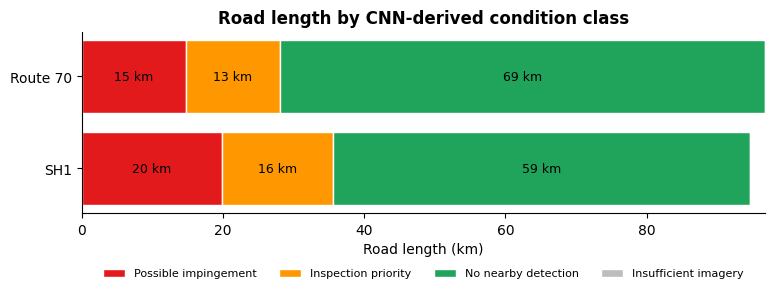

In [11]:
# ADDED 1 — KILOMETRES OF ROAD PER CONDITION CLASS

ORDER = ["possible_impingement", "inspection_priority", "no_detected_landslide_not_safe", "unknown_insufficient_imagery"]
NICE = {"possible_impingement": "Possible impingement", "inspection_priority": "Inspection priority",
        "no_detected_landslide_not_safe": "No nearby detection", "unknown_insufficient_imagery": "Insufficient imagery"}
COL = {"possible_impingement": "#e31a1c", "inspection_priority": "#ff9800", "no_detected_landslide_not_safe": "#20a45c", "unknown_insufficient_imagery": "#bdbdbd"}
km = lambda df: (df.groupby("class")["length_m"].sum()/1000).reindex(ORDER).fillna(0)
km_tab = pd.DataFrame({"SH1 (km)": km(sh1_assess), "Route 70 (km)": km(r70_assess)}); km_tab.loc["Total"] = km_tab.sum()
for c in ["SH1", "Route 70"]: km_tab[f"{c} (%)"] = (100*km_tab[f"{c} (km)"]/km_tab.loc["Total", f"{c} (km)"]).round(1)
km_tab.index = [NICE.get(i, i) for i in km_tab.index]; display(km_tab.round(1)); km_tab.round(1).to_csv(FIG_OUT / "ADDED1_km_per_class.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, (n_, df) in enumerate([("SH1", sh1_assess), ("Route 70", r70_assess)]):
    left = 0
    for cls in ORDER:
        v = df.loc[df["class"] == cls, "length_m"].sum()/1000
        ax.barh(k, v, left=left, color=COL[cls], edgecolor="white", label=NICE[cls] if k == 0 else None)
        if v > 8: ax.text(left + v/2, k, f"{v:.0f} km", ha="center", va="center", fontsize=9)
        left += v
ax.set_yticks([0, 1]); ax.set_yticklabels(["SH1", "Route 70"]); ax.set_xlabel("Road length (km)")
ax.spines[["top", "right"]].set_visible(False); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, -.25), frameon=False, fontsize=8)
ax.set_title("Road length by CNN-derived condition class", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_OUT / "ADDED1_km_per_class.png", dpi=220, bbox_inches="tight"); plt.show()

,SH1 North,SH1 South,Route 70,Pooled
≤ 0 m,31.9,28.6,49.9,34.8
≤ 10 m,39.0,36.9,60.3,42.8
≤ 25 m,44.9,44.7,66.5,49.2
≤ 50 m,52.7,53.1,74.1,57.1
≤ 75 m,58.1,59.0,78.0,62.3
≤ 100 m,63.5,65.2,80.1,67.2
≤ 150 m,72.5,74.8,84.5,75.4
≤ 200 m,79.7,81.9,86.9,81.6
≤ 300 m,87.2,89.3,94.2,89.1


Median distance from a GNS source to the nearest CNN polygon: 27 m


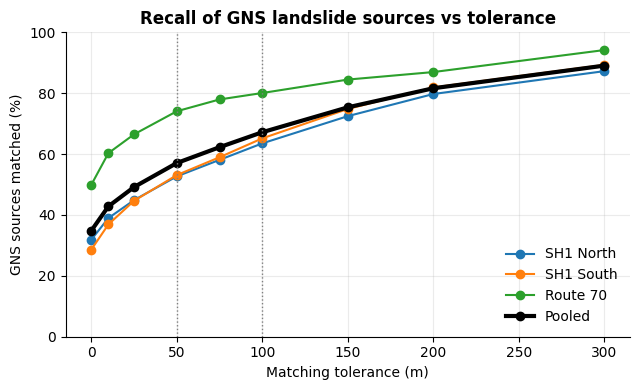

In [12]:
# ADDED 2 — RECALL OF GNS SOURCES vs MATCHING TOLERANCE

from shapely.strtree import STRtree
TOL = [0, 10, 25, 50, 75, 100, 150, 200, 300]; curves, dist_all = {}, []
for name, data in CORRIDORS.items():
    pr = data["pred"].reset_index(drop=True); pts = gns[(gns["corridor"] == name) & gns["observed"]]
    if pr.empty or pts.empty: continue
    nearest = STRtree(list(pr.geometry)).nearest(list(pts.geometry))
    d = np.array([p.distance(pr.geometry.iloc[int(i)]) for p, i in zip(pts.geometry, nearest)])
    curves[name] = [100*np.mean(d <= t) for t in TOL]; dist_all.append(d)
pooled = np.concatenate(dist_all); curves["Pooled"] = [100*np.mean(pooled <= t) for t in TOL]
curve_df = pd.DataFrame(curves, index=[f"≤ {t} m" for t in TOL]).round(1); display(curve_df)
print(f"Median distance from a GNS source to the nearest CNN polygon: {np.median(pooled):.0f} m")
curve_df.to_csv(FIG_OUT / "ADDED2_recall_vs_tolerance.csv")
fig, ax = plt.subplots(figsize=(6.5, 4))
for n_, v in curves.items(): ax.plot(TOL, v, marker="o", lw=3 if n_ == "Pooled" else 1.5, color="black" if n_ == "Pooled" else None, label=n_)
for t in (50, 100): ax.axvline(t, color="grey", ls=":", lw=1)
ax.set_xlabel("Matching tolerance (m)"); ax.set_ylabel("GNS sources matched (%)"); ax.set_ylim(0, 100); ax.grid(alpha=.25)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.set_title("Recall of GNS landslide sources vs tolerance", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_OUT / "ADDED2_recall_vs_tolerance.png", dpi=220); plt.show()

In [13]:
# ADDED 3 — PIXEL-LEVEL PRECISION / RECALL / F1 / IoU vs GNS POLYGONS (if published)

layers = requests.get(GNS_BASE, params={"f": "json"}, timeout=60).json().get("layers", [])
poly_ids = []
for l in layers:
    d = requests.get(f"{GNS_BASE}/{l['id']}", params={"f": "json"}, timeout=60).json()
    print(l["id"], "|", d.get("name"), "|", d.get("geometryType"))
    if d.get("geometryType") == "esriGeometryPolygon": poly_ids.append(l["id"])
HAVE_POLY, gp = bool(poly_ids), None
if not HAVE_POLY:
    print("\nNo polygon layer is published by GNS – pixel-level IoU cannot be computed (use ADDED 4's point proxy).")
else:
    cache = FIG_OUT / "GNS_polygons.geojson"
    if cache.exists(): gp = gpd.read_file(cache).to_crs(2193)
    else:
        xmin, ymin, xmax, ymax = all_roads.buffer(1200).bounds; feats, off = [], 0
        while True:
            r = requests.get(f"{GNS_BASE}/{poly_ids[0]}/query", params={"where": "1=1", "geometry": f"{xmin},{ymin},{xmax},{ymax}",
                "geometryType": "esriGeometryEnvelope", "inSR": 2193, "outSR": 4326, "spatialRel": "esriSpatialRelIntersects",
                "outFields": "*", "returnGeometry": "true", "resultRecordCount": 1000, "resultOffset": off, "f": "geojson"}, timeout=120).json()
            b = r.get("features", []); feats += b
            if len(b) < 1000: break
            off += 1000
        gp = gpd.GeoDataFrame.from_features(feats, crs=4326).to_crs(2193); gp.to_crs(4326).to_file(cache, driver="GeoJSON")
    gp["geometry"] = gp.geometry.buffer(0); gp = gp[gp.geometry.notna() & ~gp.geometry.is_empty].reset_index(drop=True)
    print("\nGNS polygons:", len(gp))
    EVAL = {"SH1": (SH1_OUT, unary_union([road_unions["SH1 North"], road_unions["SH1 South"]])), "Route 70": (R70_OUT, road_unions["Route 70"])}
    rows = []
    for name, (out_dir, road) in EVAL.items():
        buf = road.buffer(1000); tp = fp = fn = tn = 0
        for f in (out_dir / "tile_results").glob("C_*/binary.tif"):
            with rasterio.open(f) as src: b_ = src.read(1); T = src.transform; bnds = src.bounds
            idx = gp.sindex.query(box(*bnds), predicate="intersects")
            ref = (rasterize([(g, 1) for g in gp.geometry.iloc[idx]], out_shape=b_.shape, transform=T, fill=0, dtype="uint8").astype(bool) if len(idx) else np.zeros(b_.shape, bool))
            inbuf = rasterize([(buf, 1)], out_shape=b_.shape, transform=T, fill=0, dtype="uint8").astype(bool)
            obs = np.isin(b_, (0, 1)) & inbuf; pred = (b_ == 1)
            tp += int((pred & ref & obs).sum()); fp += int((pred & ~ref & obs).sum()); fn += int((~pred & ref & obs).sum()); tn += int((~pred & ~ref & obs).sum())
        p = tp/(tp+fp) if tp+fp else np.nan; r_ = tp/(tp+fn) if tp+fn else np.nan
        rows.append({"corridor": name, "TP_px": tp, "FP_px": fp, "FN_px": fn, "TN_px": tn, "precision": p, "recall": r_,
                     "F1": 2*p*r_/(p+r_) if tp else 0.0, "IoU": tp/(tp+fp+fn) if tp+fp+fn else np.nan})
    pix = pd.DataFrame(rows); t = pix[["TP_px", "FP_px", "FN_px", "TN_px"]].sum(); p_ = t.TP_px/(t.TP_px+t.FP_px); r2 = t.TP_px/(t.TP_px+t.FN_px)
    pix.loc[len(pix)] = ["Pooled", *t.values, p_, r2, 2*p_*r2/(p_+r2), t.TP_px/(t.TP_px+t.FP_px+t.FN_px)]
    pix[["precision", "recall", "F1", "IoU"]] = pix[["precision", "recall", "F1", "IoU"]].round(3)
    display(pix); pix.to_csv(FIG_OUT / "ADDED3_pixel_level_accuracy.csv", index=False)
    print("Reference: the model's published result on its Haiti test set: F1 0.341, precision 0.525, recall 0.252 (Monopoli et al., 2024).")

0 | Kaikoura 2016 Landslide Source Location V2 | esriGeometryPoint
1 | Kaikoura 2016 Fault Ruptures 250K | esriGeometryPolyline
2 | EIL Probability | None
3 | EIL Probability for 100 year PGA  | None
4 | EILD_V2_EILProb32_PGA100 | None
5 | EILD_V2_EILProb256_PGA100 | None
6 | EILD_V2_EILProb512_PGA100 | None
7 | EIL Probability for 250 year PGA  | None
8 | EILD_V2_EILProb32_PGA250 | None
9 | EILD_V2_EILProb256_PGA250 | None
10 | EILD_V2_EILProb512_PGA250 | None
11 | EIL Probability for 500 year PGA  | None
12 | EILD_V2_EILProb32_PGA500 | None
13 | EILD_V2_EILProb256_PGA500 | None
14 | EILD_V2_EILProb512_PGA500 | None
15 | EIL Probability for 1000 year PGA  | None
16 | EILD_V2_EILProb32_PGA1000 | None
17 | EILD_V2_EILProb256_PGA1000 | None
18 | EILD_V2_EILProb512_PGA1000 | None

No polygon layer is published by GNS – pixel-level IoU cannot be computed (use ADDED 4's point proxy).


In [14]:
# ADDED 4 — SHARE OF CNN POLYGONS SUPPORTED BY THE INVENTORY

rows = []
for name, data in CORRIDORS.items():
    pr = data["pred"].reset_index(drop=True)
    if pr.empty: continue
    pts = gns[gns["corridor"] == name]
    hit_pt = sum(len(pts.sindex.query(g.buffer(50), predicate="intersects")) > 0 for g in pr.geometry)
    row = {"corridor": name, "CNN_polygons": len(pr), "within_50m_of_GNS_point": hit_pt, "pct_point_proxy": round(100*hit_pt/len(pr), 1)}
    if HAVE_POLY and gp is not None:
        hp = sum(len(gp.sindex.query(g, predicate="intersects")) > 0 for g in pr.geometry)
        row.update({"overlap_GNS_polygon": hp, "pct_polygon_overlap": round(100*hp/len(pr), 1)})
    rows.append(row)
obj = pd.DataFrame(rows); display(obj); obj.to_csv(FIG_OUT / "ADDED4_object_level_support.csv", index=False)
print("The point-proxy is a LOWER bound: GNS stores one point per landslide, but a CNN polygon can lie far from that point.")

,corridor,CNN_polygons,within_50m_of_GNS_point,pct_point_proxy
0,SH1 North,596,128,21.5
1,SH1 South,397,58,14.6
2,Route 70,1014,98,9.7


The point-proxy is a LOWER bound: GNS stores one point per landslide, but a CNN polygon can lie far from that point.


/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


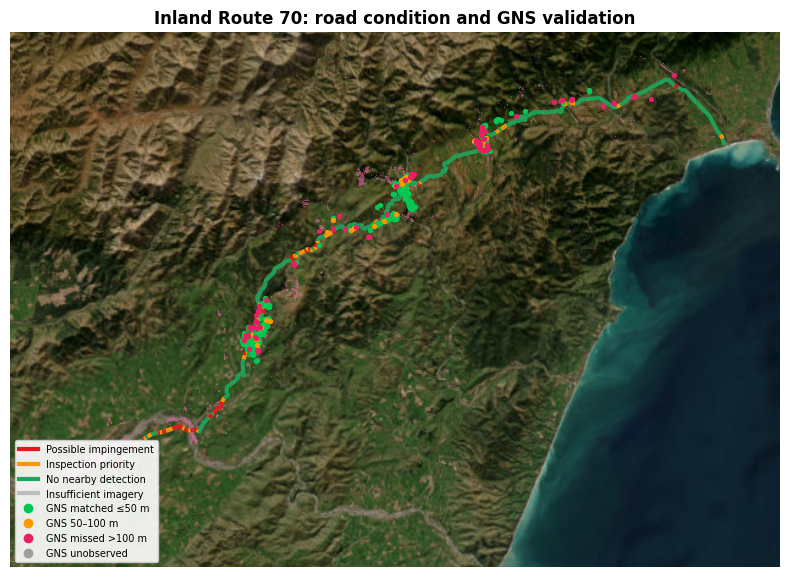

/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


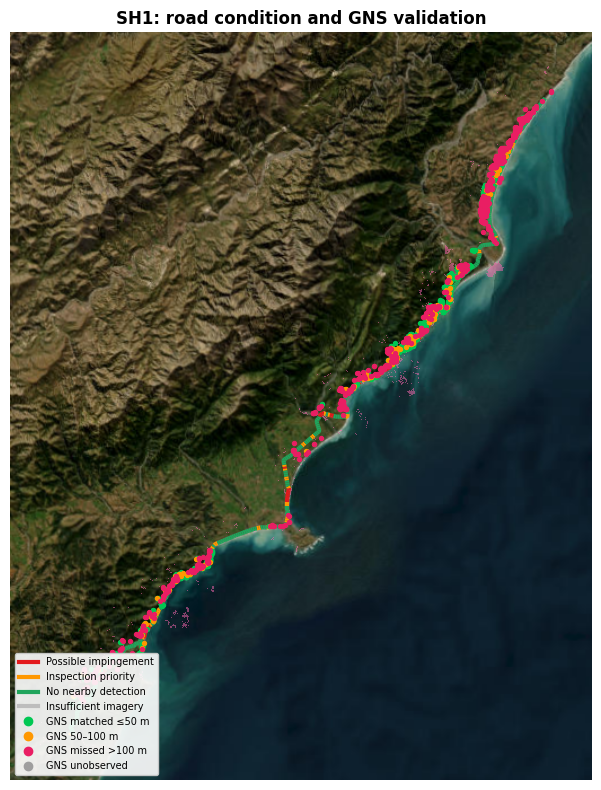

All figures and CSVs are in: /content/work/figures


In [15]:
# ADDED 5 — PUBLICATION-STYLE MAPS (classes + detections + GNS match status)

try:
    import contextily as cx
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "contextily"]); import contextily as cx
STATUS_COL = {"MATCHED_50M": "#00c853", "NEAR_100M": "#ff9800", "MISSED": "#e91e63", "UNOBSERVED": "#9e9e9e"}
def make_map(assess, preds, corridor_names, title, fname):
    fig, ax = plt.subplots(figsize=(8, 8))
    preds.plot(ax=ax, color="#ff69b4", alpha=.5, zorder=2)
    for cls in ORDER: assess[assess["class"] == cls].plot(ax=ax, color=COL[cls], lw=3, zorder=3)
    g = gns[gns["corridor"].isin(corridor_names)]
    for st, c in STATUS_COL.items(): g[g["match_status"] == st].plot(ax=ax, color=c, markersize=8, zorder=4)
    try: cx.add_basemap(ax, crs="EPSG:2193", source=cx.providers.Esri.WorldImagery, attribution=False)
    except Exception as e: print("Basemap unavailable:", str(e)[:80])
    ax.set_axis_off(); ax.set_title(title, fontweight="bold")
    from matplotlib.lines import Line2D
    h = [Line2D([0], [0], color=COL[c], lw=3, label=NICE[c]) for c in ORDER]
    h += [Line2D([0], [0], marker="o", ls="", color=c, label={"MATCHED_50M": "GNS matched ≤50 m", "NEAR_100M": "GNS 50–100 m", "MISSED": "GNS missed >100 m", "UNOBSERVED": "GNS unobserved"}[s]) for s, c in STATUS_COL.items()]
    ax.legend(handles=h, loc="lower left", fontsize=7, framealpha=.9)
    plt.tight_layout(); plt.savefig(FIG_OUT / fname, dpi=220, bbox_inches="tight"); plt.show()
make_map(r70_assess, pred70, ["Route 70"], "Inland Route 70: road condition and GNS validation", "map_route70.png")
make_map(sh1_assess, pred_sh1, ["SH1 North", "SH1 South"], "SH1: road condition and GNS validation", "map_sh1.png")
print("All figures and CSVs are in:", FIG_OUT)